# Telco Customer Churn Analysis & Prediction

**Project Objective:**  
Analyze customer behavior and build machine learning models to predict customer churn.

**Dataset:** Telco Customer Churn (Kaggle)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_score, recall_score, f1_score)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("=== Dataset Info ===")
df.info()

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

df.drop('customerID', axis=1, inplace=True)

print("Data cleaning completed!")
print("Missing values after cleaning:", df.isnull().sum().sum())

Data cleaning completed!
Missing values after cleaning: 0


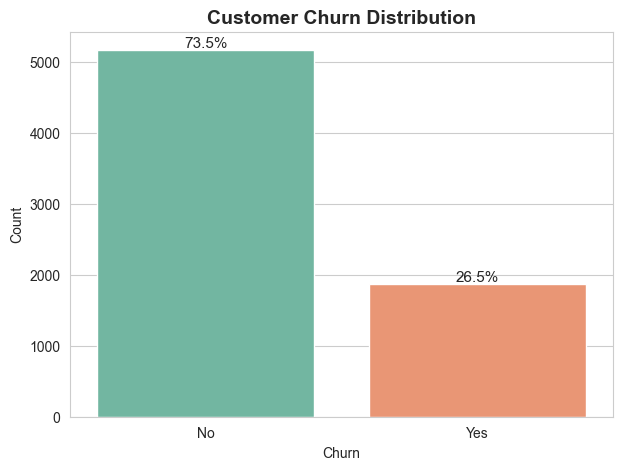

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn')
plt.ylabel('Count')

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.show()

print(df['Churn'].value_counts(normalize=True)*100)

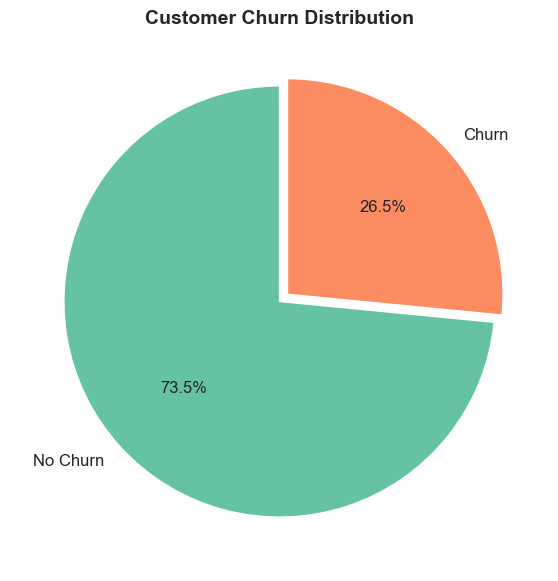

In [6]:
plt.figure(figsize=(7, 7))
churn_counts = df['Churn'].value_counts()
plt.pie(churn_counts, labels=['No Churn', 'Churn'], autopct='%1.1f%%',
        colors=['#66c2a5', '#fc8d62'], startangle=90, explode=(0, 0.05),
        textprops={'fontsize': 12})
plt.title('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.show()

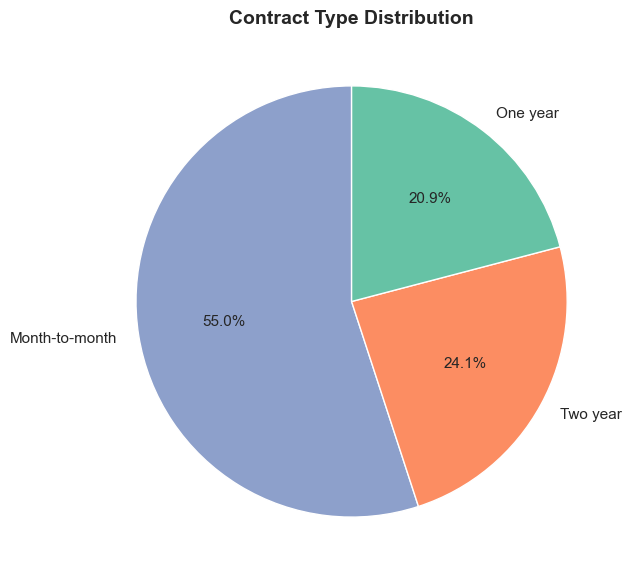

In [20]:
plt.figure(figsize=(7, 7))
contract_counts = df['Contract'].value_counts()
plt.pie(contract_counts, labels=contract_counts.index, autopct='%1.1f%%',
        colors=['#8da0cb', '#fc8d62', '#66c2a5'], startangle=90,
        textprops={'fontsize': 11})
plt.title('Contract Type Distribution', fontsize=14, fontweight='bold')
plt.show()

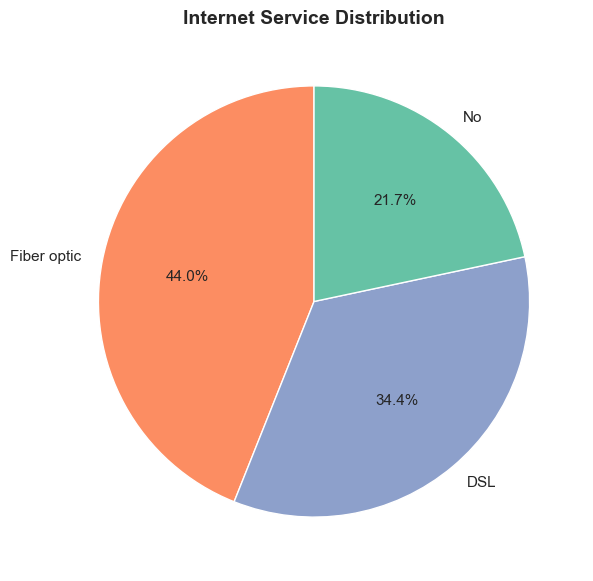

In [21]:
plt.figure(figsize=(7, 7))
internet_counts = df['InternetService'].value_counts()
plt.pie(internet_counts, labels=internet_counts.index, autopct='%1.1f%%',
        colors=['#fc8d62', '#8da0cb', '#66c2a5'], startangle=90,
        textprops={'fontsize': 11})
plt.title('Internet Service Distribution', fontsize=14, fontweight='bold')
plt.show()

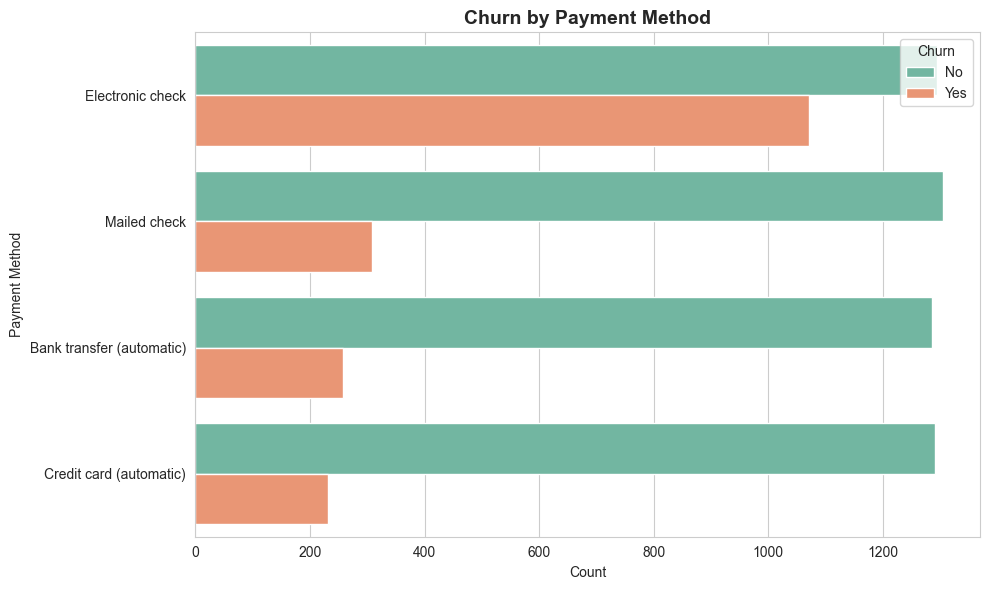

In [22]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='PaymentMethod', hue='Churn', palette='Set2')
plt.title('Churn by Payment Method', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Payment Method')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

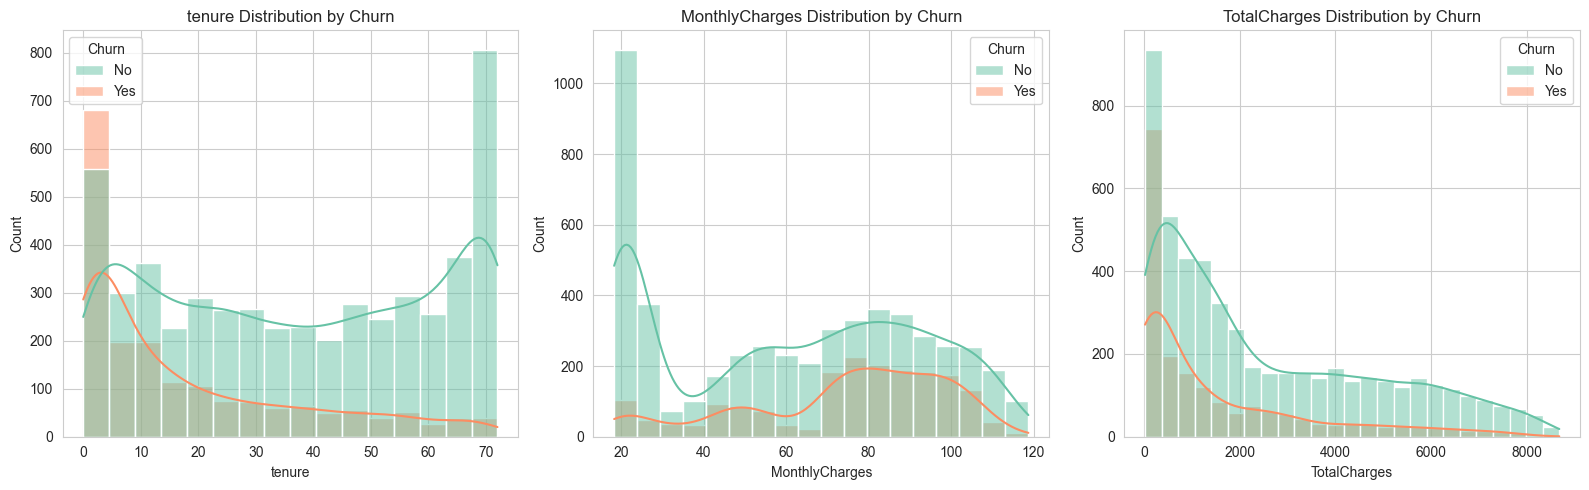

In [7]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} Distribution by Churn')

plt.tight_layout()
plt.show()

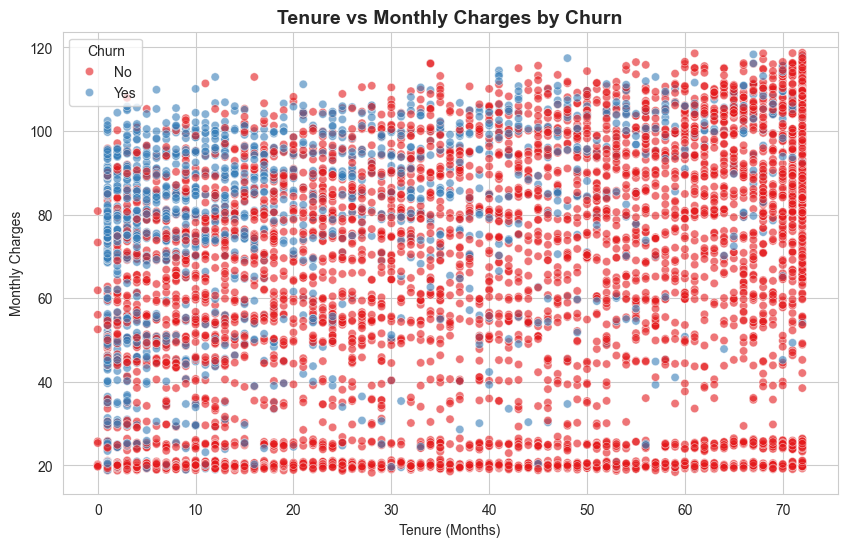

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn',
                palette='Set1', alpha=0.6)
plt.title('Tenure vs Monthly Charges by Churn', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.legend(title='Churn')
plt.show()

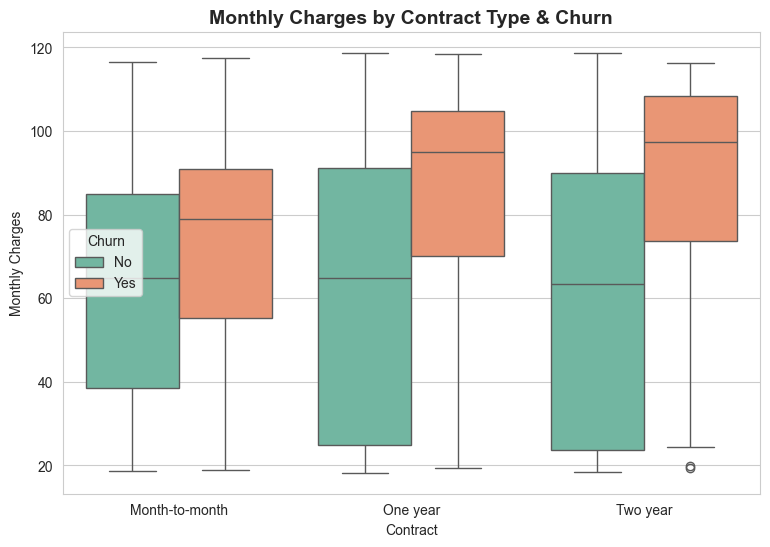

In [18]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='Contract', y='MonthlyCharges', hue='Churn', palette='Set2')
plt.title('Monthly Charges by Contract Type & Churn', fontsize=14, fontweight='bold')
plt.xlabel('Contract')
plt.ylabel('Monthly Charges')
plt.show()

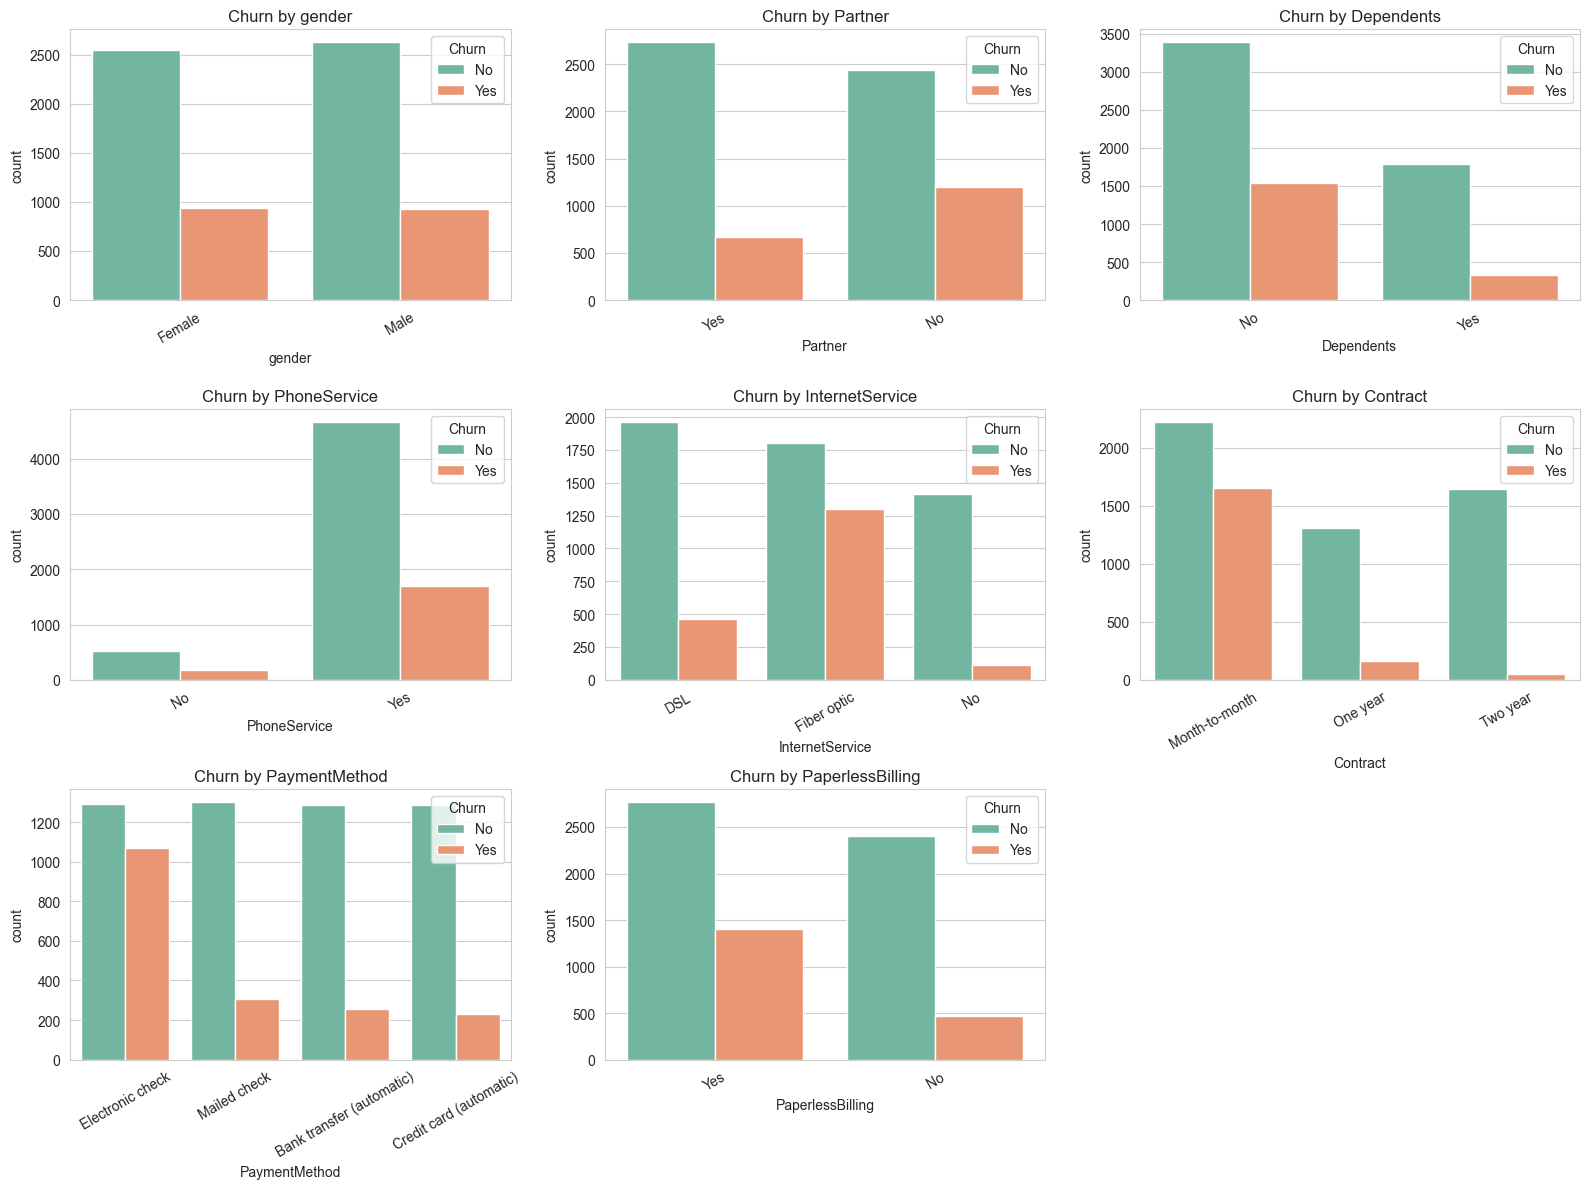

In [8]:
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService',
            'Contract', 'PaymentMethod', 'PaperlessBilling']

plt.figure(figsize=(16, 12))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(data=df, x=col, hue='Churn', palette='Set2')
    plt.title(f'Churn by {col}')
    plt.xticks(rotation=30)
    plt.legend(title='Churn')

plt.tight_layout()
plt.show()

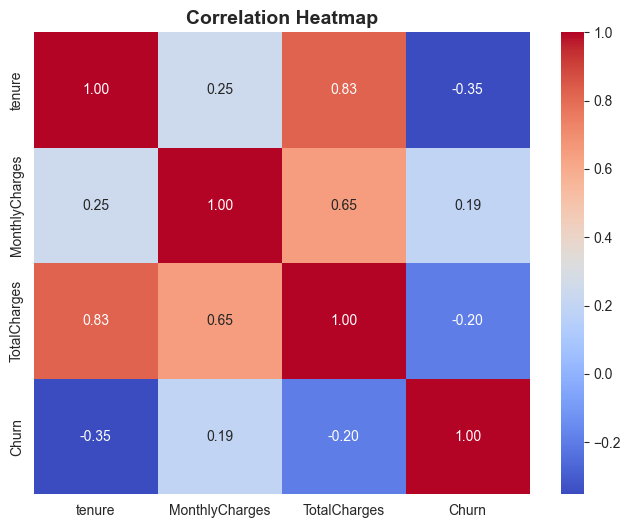

In [9]:
# Encode Churn temporarily for correlation
df_corr = df.copy()
df_corr['Churn'] = df_corr['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

In [10]:
print("="*50)
print("STATISTICAL TESTS")
print("="*50)

# 1. Mann-Whitney U Test (Numerical vs Churn)
print("\n1. Mann-Whitney U Test (Numerical Features vs Churn)\n")
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    group_yes = df[df['Churn'] == 'Yes'][col]
    group_no  = df[df['Churn'] == 'No'][col]
    stat, p = mannwhitneyu(group_yes, group_no)
    result = "Significant" if p < 0.05 else "Not Significant"
    print(f"{col:18} | p-value: {p:.4f} | {result}")

# 2. Chi-Square Test (Categorical vs Churn)
print("\n2. Chi-Square Test (Categorical Features vs Churn)\n")
for col in ['Contract', 'InternetService', 'PaymentMethod', 'Partner', 'Dependents']:
    contingency = pd.crosstab(df[col], df['Churn'])
    chi2, p, dof, expected = chi2_contingency(contingency)
    result = "Significant" if p < 0.05 else "Not Significant"
    print(f"{col:18} | p-value: {p:.4f} | {result}")

STATISTICAL TESTS

1. Mann-Whitney U Test (Numerical Features vs Churn)

tenure             | p-value: 0.0000 | Significant
MonthlyCharges     | p-value: 0.0000 | Significant
TotalCharges       | p-value: 0.0000 | Significant

2. Chi-Square Test (Categorical Features vs Churn)

Contract           | p-value: 0.0000 | Significant
InternetService    | p-value: 0.0000 | Significant
PaymentMethod      | p-value: 0.0000 | Significant
Partner            | p-value: 0.0000 | Significant
Dependents         | p-value: 0.0000 | Significant


In [11]:
# Make a copy
data = df.copy()

# Encode target
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

# Encode binary columns
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    data[col] = LabelEncoder().fit_transform(data[col])

# One-hot encode remaining categorical columns
data = pd.get_dummies(data, columns=['MultipleLines', 'InternetService', 'OnlineSecurity',
                                     'OnlineBackup', 'DeviceProtection', 'TechSupport',
                                     'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'],
                      drop_first=True)

print("Preprocessing completed!")
print("Final shape:", data.shape)
data.head()

Preprocessing completed!
Final shape: (7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


In [12]:
X = data.drop('Churn', axis=1)
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (5634, 30)
Testing set : (1409, 30)


In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }
    print(f"{name} trained successfully!")

results_df = pd.DataFrame(results).T
print("\n=== Model Performance Comparison ===")
print(results_df.round(4))

Logistic Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

=== Model Performance Comparison ===
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8048     0.6542  0.5615    0.6043   0.8426
Random Forest          0.7878     0.6298  0.4866    0.5490   0.8243
Gradient Boosting      0.7949     0.6431  0.5107    0.5693   0.8366


=== Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409



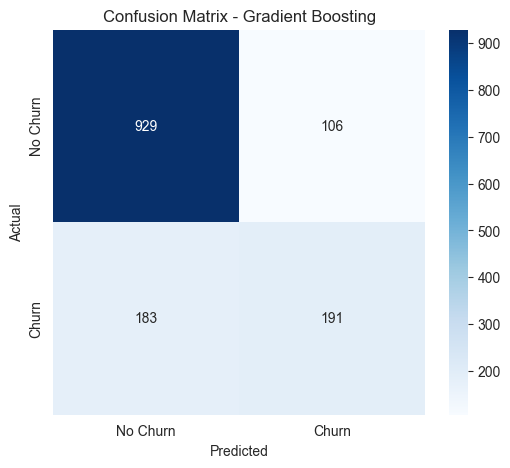

In [14]:
best_model = models["Gradient Boosting"]
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix - Gradient Boosting')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

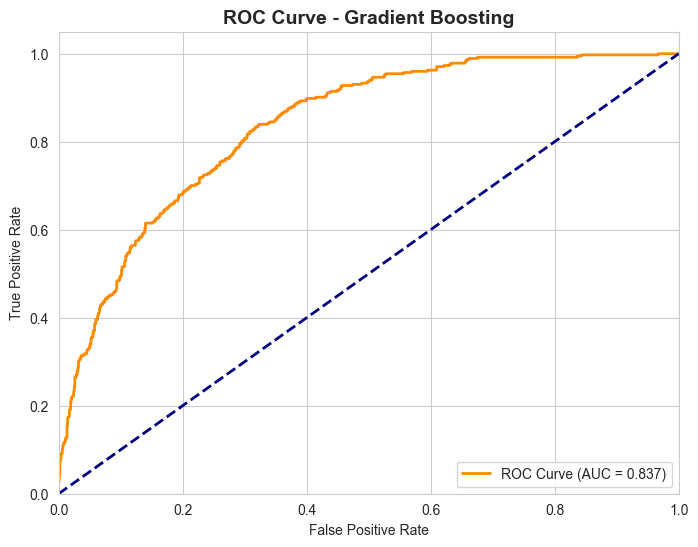

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Boosting', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

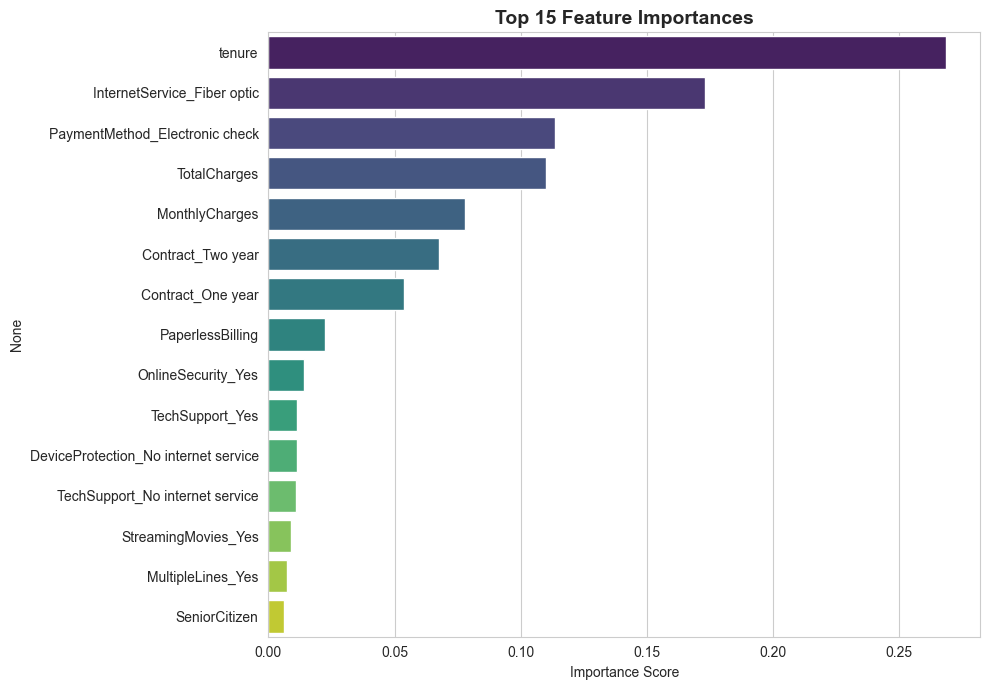

In [16]:
importances = pd.Series(best_model.feature_importances_, index=X.columns)
top_features = importances.nlargest(15)

plt.figure(figsize=(10, 7))
sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
plt.title('Top 15 Feature Importances', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [23]:
import joblib

# Save the best model
joblib.dump(best_model, 'churn_prediction_model.pkl')
print("✅ Model saved as 'churn_prediction_model.pkl'")

# Optional: Save the feature columns (very useful for Streamlit later)
joblib.dump(list(X.columns), 'model_features.pkl')
print("✅ Feature list saved as 'model_features.pkl'")

✅ Model saved as 'churn_prediction_model.pkl'
✅ Feature list saved as 'model_features.pkl'


## Conclusion

### Key Insights:
- Customers with **Month-to-month contracts** have significantly higher churn.
- Higher **MonthlyCharges** and lower **tenure** are strong indicators of churn.
- Fiber optic internet service users show higher churn rates.

### Model Performance:
- **Gradient Boosting** performed the best among the three models.
- The model can be used to identify high-risk customers for retention campaigns.

### Business Recommendations:
1. Offer better long-term contract incentives.
2. Focus retention efforts on high monthly charge + low tenure customers.
3. Investigate service quality issues with Fiber optic users.